# 고도 해상도 — 핸드폰을 높여 가며 norm이 얼마나 줄어드나 (Step8c)

> 2026-10-28 녹음 `phone_elev_00` ~ `_03` · 계산: [`doa/doa_stream.py`](../doa/doa_stream.py), [`doa/mask_phat.py`](../doa/mask_phat.py) · 커널: `Tools/.venv`
> 결론은 마지막 절에 **결론 후보**로만 적는다.

**질문:** 평면 배열은 고도를 직접 못 재지만, 음원이 위로 올라가면 수평 성분이 줄어 **norm(지연 벡터 크기 ÷ 수평 음원일 때 크기)이 cos(고도각)으로 줄어든다.** 이 차이로 "낮은 소리 대 높은 소리"를 가를 수 있나?

| 녹음 | 높이 h | 수평 거리 l | 고도각 atan(h ÷ l) | 기대 norm 비율 cos(고도각) |
|---|---|---|---|---|
| `phone_elev_00` | 0 cm | 100 cm | 0.0° | 1.000 |
| `phone_elev_01` | 12 cm | 100 cm | 6.8° | 0.993 |
| `phone_elev_02` | 22 cm | 100 cm | 12.4° | 0.977 |
| `phone_elev_03` | 44 cm | 100 cm | 23.7° | 0.916 |

(계획은 0 · 10 · 20 · 30°였으나 실제 높이로 계산. 사용자 측정값.)

**Step8c 기준 (2026-10-26 확정, 20°·30° 자리에 실제 12.4°·23.7°를 쓴다):**
- 고도 해상도: 0° 단계와 높은 단계(23.7°)의 창별 norm 비율 p5 ~ p95 구간이 겹치지 않음
- 고도: arccos(norm ÷ k0)이 atan(h ÷ l)의 ±10° 안 (높은 두 단계). k0 = 0° 단계 norm 중앙값

**계산:** PC가 원음으로 다시 계산한다 (보드는 켤 때 배운 배경을 써서 믿기 어렵다, D8d-4). 배경 = 녹음 앞 조용한 구간 (올바른 배경)과 배경 없음 두 가지. 창 0.5 s · 이동 0.25 s. **norm 범위 검사(0.5 ~ 1.3)는 빼고** 봉우리·닫힘만 본다 — norm 검사가 높은 음원 창을 잘라 버리면 분포를 볼 수 없다.
**한계:** 핸드폰 스피커, 책 더미 위(반사), 1 m 거리. 방위가 계획(0°)과 다르다 (1절).

In [1]:
import sys
import numpy as np, soundfile as sf, csv
import matplotlib.pyplot as plt
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic") if f in _have), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
sys.path.insert(0, ".."); sys.path.insert(0, "../doa")
import doa_stream as ds, gcc_phat as g
DELAY = ds.channel_delays_us()
import mask_phat as mp
ds.DELAY_US = DELAY
FS = 12500; A = mp.args(); POS, D = ds.positions()
mp.FREQ_IN = (mp.FREQ >= 300) & (mp.FREQ <= 3000)
H = {"phone_elev_00": 0, "phone_elev_01": 12, "phone_elev_02": 22, "phone_elev_03": 44}; L_CM = 100
EL = {k: np.degrees(np.arctan(h / L_CM)) for k, h in H.items()}
print("채널 지연 [us]:", np.round(DELAY, 1), "· 고도각:", {k[-2:]: round(v, 1) for k, v in EL.items()})

채널 지연 [us]: [  0.  -23.1   4.3] · 고도각: {'00': np.float64(0.0), '01': np.float64(6.8), '02': np.float64(12.4), '03': np.float64(23.7)}


## 1. 녹음 불러오기, 소리 시작, 보드 결과

보드 결과(`doa_mcu.csv`)의 방위·norm도 같이 본다 (보드 배경 기준).

In [2]:
def band_p(seg):
    w = np.hanning(len(seg)); X = np.fft.rfft((seg - seg.mean()) * w); f = np.fft.rfftfreq(len(seg), 1 / FS)
    m = (f >= 300) & (f < 3000); return 2 * np.sum(np.abs(X[m]) ** 2) / (len(seg) * np.sum(w ** 2))
REC = {}
for lab in H:
    x, _ = sf.read(f"../dumps/stream/{lab}/seg_000.wav", dtype="float64"); x = (x - x.mean(0)).T
    t = np.arange(0, x.shape[1] / FS - 1, 0.5)
    Lv = np.array([10 * np.log10(2 * band_p(x[0, int(s * FS):int(s * FS) + FS]) + 1e-30) for s in t])
    fl0 = np.median(Lv[(t >= 1) & (t < 5)]); hi = (t >= 1) & (Lv > fl0 + 10)
    on = t[np.argmax(np.convolve(hi, np.ones(6, int), "full")[5:][:len(t)] == 6)]
    bg = ds.cross_spectra(x[:, int(0.5 * FS):int((on - 1) * FS)], A.block, mp.NFFT)
    s0 = np.arange(int((on + 1) * FS), x.shape[1] - 6250, int(0.25 * FS))
    r = list(csv.DictReader(open(f"../dumps/stream/{lab}/doa_mcu.csv")))
    bv = [q for q in r if int(q["flags"]) & 1]
    REC[lab] = dict(x=x, onset=on, bg=bg, s0=s0)
    print(f"{lab}: 소리 시작 {on:.1f} s, 배경 {on - 1.5:.1f} s 분량, 창 {len(s0)}개 · 보드 유효 {len(bv)}/{len(r)}, "
          f"보드 방위 중앙 {np.median([float(q['angle']) for q in bv]):.1f}°, 보드 norm 중앙 {np.median([float(q['norm']) for q in bv]):.3f}")

phone_elev_00: 소리 시작 9.0 s, 배경 7.5 s 분량, 창 198개 · 보드 유효 204/244, 보드 방위 중앙 -118.9°, 보드 norm 중앙 0.716


phone_elev_01: 소리 시작 8.5 s, 배경 7.0 s 분량, 창 200개 · 보드 유효 173/244, 보드 방위 중앙 -114.1°, 보드 norm 중앙 0.594


phone_elev_02: 소리 시작 7.5 s, 배경 6.0 s 분량, 창 204개 · 보드 유효 13/244, 보드 방위 중앙 -114.9°, 보드 norm 중앙 0.521
phone_elev_03: 소리 시작 7.0 s, 배경 5.5 s 분량, 창 206개 · 보드 유효 204/244, 보드 방위 중앙 -117.8°, 보드 norm 중앙 0.576


## 2. 창마다 norm (PC, 올바른 배경 · 배경 없음)

In [3]:
def run_window(x, s, bg, sub):
    S = ds.cross_spectra(x[:, s:s + 6250], A.block, mp.NFFT)
    mask = mp.make_mask(S, "full", None)
    cur = [mp.phat_curve(S[k] - bg[k] if sub else S[k], mask) for k in range(3)]
    tau = [cur[k][2] - (DELAY[j] - DELAY[i]) * 1e-6 * FS for k, (i, j) in enumerate(g.PAIRS)]
    ang, norm = g.tdoa_to_angle(tau, FS, POS)
    ok = min(c[3] for c in cur) >= A.min_peak and abs(tau[0] + tau[2] - tau[1]) <= A.max_closure   # norm 검사 뺌
    return ang, norm, ok
OUT = {}
for lab, R in REC.items():
    for sub in (True, False):
        rs = np.array([run_window(R["x"], s, R["bg"], sub) for s in R["s0"]], dtype=float)
        OUT[(lab, sub)] = rs
        a, n, ok = rs[:, 0], rs[:, 1], rs[:, 2].astype(bool)
        print(f"{lab} {'올바른 배경' if sub else '배경 없음 '}: 통과 {ok.sum()}/{len(ok)} · 방위 중앙 {np.median(a[ok]):7.1f}° · norm 중앙 {np.median(n[ok]):.3f} (p5 {np.percentile(n[ok], 5):.3f} ~ p95 {np.percentile(n[ok], 95):.3f})")

phone_elev_00 올바른 배경: 통과 198/198 · 방위 중앙  -118.7° · norm 중앙 0.716 (p5 0.654 ~ p95 0.747)


phone_elev_00 배경 없음 : 통과 198/198 · 방위 중앙  -118.7° · norm 중앙 0.715 (p5 0.653 ~ p95 0.747)


phone_elev_01 올바른 배경: 통과 183/200 · 방위 중앙  -114.0° · norm 중앙 0.587 (p5 0.510 ~ p95 0.646)


phone_elev_01 배경 없음 : 통과 183/200 · 방위 중앙  -114.0° · norm 중앙 0.587 (p5 0.508 ~ p95 0.645)


phone_elev_02 올바른 배경: 통과 196/204 · 방위 중앙  -117.2° · norm 중앙 0.405 (p5 0.298 ~ p95 0.506)


phone_elev_02 배경 없음 : 통과 196/204 · 방위 중앙  -117.2° · norm 중앙 0.404 (p5 0.297 ~ p95 0.506)


phone_elev_03 올바른 배경: 통과 202/206 · 방위 중앙  -117.8° · norm 중앙 0.577 (p5 0.555 ~ p95 0.610)


phone_elev_03 배경 없음 : 통과 202/206 · 방위 중앙  -117.8° · norm 중앙 0.576 (p5 0.554 ~ p95 0.609)


## 3. norm 비율과 고도 추정

k0 = 0° 단계의 norm 중앙값. 비율 = norm ÷ k0. 기대 = cos(고도각). 추정 고도 = arccos(min(비율, 1)).

▶ **예측 지점 (T1)** — 표의 기대값(0.993 · 0.977 · 0.916)을 보고, 실측 비율이 이 순서대로 줄어들지 먼저 예측한다.

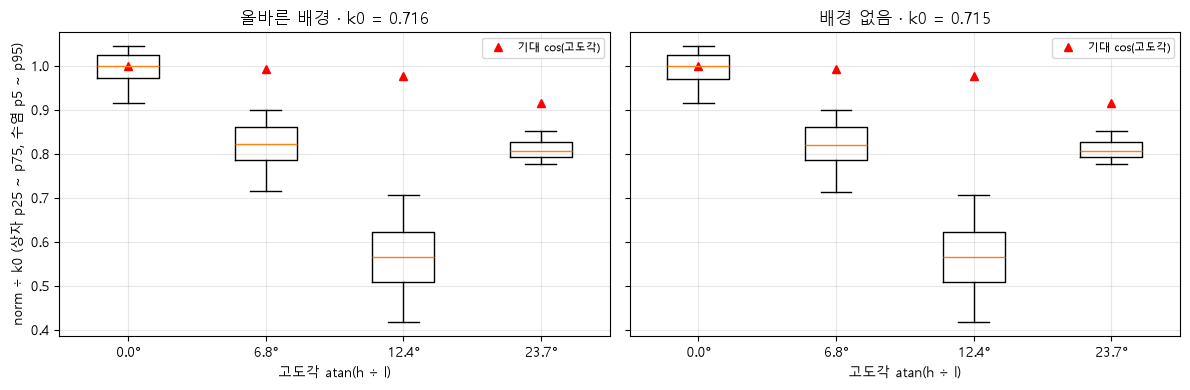

올바른 배경
    0.0°: 비율 중앙 1.000 (기대 1.000) · p5 ~ p95 0.914 ~ 1.044 · 추정 고도 중앙   0.6°
    6.8°: 비율 중앙 0.821 (기대 0.993) · p5 ~ p95 0.712 ~ 0.903 · 추정 고도 중앙  34.8°
   12.4°: 비율 중앙 0.565 (기대 0.977) · p5 ~ p95 0.417 ~ 0.708 · 추정 고도 중앙  55.6°
   23.7°: 비율 중앙 0.807 (기대 0.915) · p5 ~ p95 0.776 ~ 0.852 · 추정 고도 중앙  36.2°
배경 없음
    0.0°: 비율 중앙 1.000 (기대 1.000) · p5 ~ p95 0.914 ~ 1.044 · 추정 고도 중앙   0.3°
    6.8°: 비율 중앙 0.821 (기대 0.993) · p5 ~ p95 0.711 ~ 0.902 · 추정 고도 중앙  34.9°
   12.4°: 비율 중앙 0.565 (기대 0.977) · p5 ~ p95 0.416 ~ 0.707 · 추정 고도 중앙  55.6°
   23.7°: 비율 중앙 0.806 (기대 0.915) · p5 ~ p95 0.776 ~ 0.852 · 추정 고도 중앙  36.3°


In [4]:
RES = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a_, sub in zip(ax, (True, False)):
    k0 = np.median(OUT[("phone_elev_00", sub)][:, 1][OUT[("phone_elev_00", sub)][:, 2].astype(bool)])
    data = []
    for lab in H:
        rs = OUT[(lab, sub)]; ok = rs[:, 2].astype(bool); ratio = rs[ok, 1] / k0
        est = np.degrees(np.arccos(np.clip(ratio, -1, 1)))
        RES[(lab, sub)] = dict(ratio=ratio, est=est, k0=k0)
        data.append(ratio)
    a_.boxplot(data, whis=(5, 95), showfliers=False)
    a_.plot(range(1, 5), [np.cos(np.radians(EL[l])) for l in H], "r^", label="기대 cos(고도각)")
    a_.set_xticks(range(1, 5), [f"{EL[l]:.1f}°" for l in H]); a_.set_xlabel("고도각 atan(h ÷ l)")
    a_.set_title(f"{'올바른 배경' if sub else '배경 없음'} · k0 = {k0:.3f}"); a_.grid(alpha=.3); a_.legend(fontsize=8)
ax[0].set_ylabel("norm ÷ k0 (상자 p25 ~ p75, 수염 p5 ~ p95)"); plt.tight_layout(); plt.show()
for sub in (True, False):
    print("올바른 배경" if sub else "배경 없음")
    for lab in H:
        r = RES[(lab, sub)]
        print(f"  {EL[lab]:5.1f}°: 비율 중앙 {np.median(r['ratio']):.3f} (기대 {np.cos(np.radians(EL[lab])):.3f}) · p5 ~ p95 {np.percentile(r['ratio'], 5):.3f} ~ {np.percentile(r['ratio'], 95):.3f} · 추정 고도 중앙 {np.median(r['est']):5.1f}°")

## 4. 기준 판정

In [5]:
for sub in (True, False):
    r0, r3 = RES[("phone_elev_00", sub)], RES[("phone_elev_03", sub)]
    lo0, hi3 = np.percentile(r0["ratio"], 5), np.percentile(r3["ratio"], 95)
    sep = hi3 < lo0
    print(f"{'올바른 배경' if sub else '배경 없음 '}: 고도 해상도 — 0° p5 {lo0:.3f} 대 23.7° p95 {hi3:.3f} → {'겹치지 않음 (통과)' if sep else '겹침 (미달)'}")
    for lab in ("phone_elev_02", "phone_elev_03"):
        e = np.median(RES[(lab, sub)]["est"]); ok = abs(e - EL[lab]) <= 10
        print(f"      고도 {EL[lab]:4.1f}°: 추정 중앙 {e:5.1f}° (차이 {e - EL[lab]:+5.1f}°) → {'통과' if ok else '미달'}")

올바른 배경: 고도 해상도 — 0° p5 0.914 대 23.7° p95 0.852 → 겹치지 않음 (통과)
      고도 12.4°: 추정 중앙  55.6° (차이 +43.2°) → 미달
      고도 23.7°: 추정 중앙  36.2° (차이 +12.4°) → 미달
배경 없음 : 고도 해상도 — 0° p5 0.914 대 23.7° p95 0.852 → 겹치지 않음 (통과)
      고도 12.4°: 추정 중앙  55.6° (차이 +43.2°) → 미달
      고도 23.7°: 추정 중앙  36.3° (차이 +12.5°) → 미달


## 5. 결론 후보 (사용자 확인 전)

- 위 4절 판정과 3절 그림을 근거로 쓴다.
- 아직 모르는 것: 방위가 계획(0°)과 다른 이유, 책 더미 반사의 영향, 실제 원거리(평면파)에서의 비율.